# Data Challenge: Análisis Histórico de San Lorenzo de Almagro

## 1. Introducción
* **Descripción del dataset:** El conjunto de datos recopila el historial de partidos de la Primera División del fútbol argentino extraídos de registros históricos.
* **Fuente:** Repositorio público `futbol-argentino-data` (GitHub - rhinoah).
* **Preguntas guía:** 
  1. ¿Cómo varió el rendimiento y promedio de gol de San Lorenzo en condición de local vs. visitante a lo largo de los años?
  2. ¿En qué etapas históricas San Lorenzo registró su mayor promedio de gol y cómo impactó eso en sus campañas más exitosas?

## 2. Exploración inicial

El repositorio guarda **un archivo CSV por temporada** dentro de `futbol-argentino-data/data/`. Primero listamos los archivos disponibles y después los unimos en un único DataFrame para explorarlo.

In [1]:
#Listamos todos los archivos .csv que existen adentro para ver sus rutas exactas
import os

print("\n--- Archivos encontrados en el repositorio ---")
for raiz, directorios, archivos in os.walk("futbol-argentino-data"):
    for archivo in archivos:
        if archivo.endswith(".csv") or archivo.endswith(".json") or archivo.endswith(".xlsx"):
            ruta_completa = os.path.join(raiz, archivo)
            print(ruta_completa)


--- Archivos encontrados en el repositorio ---
futbol-argentino-data\data\partidos-1985.csv
futbol-argentino-data\data\partidos-1986.csv
futbol-argentino-data\data\partidos-1987.csv
futbol-argentino-data\data\partidos-1988.csv
futbol-argentino-data\data\partidos-1989.csv
futbol-argentino-data\data\partidos-1990.csv
futbol-argentino-data\data\partidos-1991.csv
futbol-argentino-data\data\partidos-1992.csv
futbol-argentino-data\data\partidos-1993.csv
futbol-argentino-data\data\partidos-1994.csv
futbol-argentino-data\data\partidos-1995.csv
futbol-argentino-data\data\partidos-1996.csv
futbol-argentino-data\data\partidos-1997.csv
futbol-argentino-data\data\partidos-1998.csv
futbol-argentino-data\data\partidos-1999.csv
futbol-argentino-data\data\partidos-2000.csv
futbol-argentino-data\data\partidos-2001.csv
futbol-argentino-data\data\partidos-2002.csv
futbol-argentino-data\data\partidos-2003.csv
futbol-argentino-data\data\partidos-2004.csv
futbol-argentino-data\data\partidos-2005.csv
futbol-

In [2]:
# Paso 1: Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import re

# Paso 2: Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Paso 3: Búsqueda y unión de todos los archivos CSV anuales (1985 - 2026)
# Usamos glob para tomar solo los CSV que están directamente en la carpeta 'data' 
# (así evitamos la subcarpeta 'sin-fecha' y no duplicamos el 2024)
ruta_archivos = os.path.join("futbol-argentino-data", "data", "partidos-*.csv")
archivos_csv = sorted(glob.glob(ruta_archivos))

print(f"Cantidad de archivos anuales encontrados: {len(archivos_csv)}")

lista_df = []

for archivo in archivos_csv:
    df_temp = pd.read_csv(archivo)
    
    # Extraemos el año del nombre del archivo (ej: 'partidos-1995.csv' -> 1995)
    # Esto nos asegura tener la columna 'anio_archivo' lista para analizar por décadas
    anio_match = re.search(r'(\d{4})', os.path.basename(archivo))
    if anio_match:
        df_temp['anio_archivo'] = int(anio_match.group(1))
        
    lista_df.append(df_temp)

# Unimos (concatenamos) todos los años en un único DataFrame maestro
df = pd.concat(lista_df, ignore_index=True)

# Paso 4: Dimensiones del dataset unificado
print(f"Dimensiones totales del dataset (Filas, Columnas): {df.shape}")

# Paso 5: Vista previa de las primeras filas y nombres de columnas
print("\nColumnas disponibles:", df.columns.tolist())
display(df.head())

# Paso 6: Estructura técnica y tipos de datos
print("\n--- Información técnica del Dataset ---")
df.info()

# Paso 7: Resumen estadístico de variables numéricas
print("\n--- Estadísticas Descriptivas ---")
display(df.describe())

Cantidad de archivos anuales encontrados: 42
Dimensiones totales del dataset (Filas, Columnas): (50087, 18)

Columnas disponibles: ['date', 'time', 'home_team', 'away_team', 'home_score', 'away_score', 'home_pens', 'away_pens', 'tournament', 'season', 'phase', 'group', 'matchday', 'venue', 'neutral', 'source', 'status', 'anio_archivo']


,date,time,home_team,away_team,home_score,away_score,home_pens,away_pens,tournament,season,phase,group,matchday,venue,neutral,source,status,anio_archivo
0,1985-07-06,NaN,Boca Juniors,Racing (C),3,1,NaN,NaN,Primera Division,1985,zonas,NaN,Fecha 1,NaN,False,https://es.wikipedia.org/wiki/Campeonato_de_Pr...,NaN,1985
1,1985-07-06,NaN,Deportivo Español,Newell's Old Boys,1,1,NaN,NaN,Primera Division,1985,zonas,NaN,Fecha 1,NaN,False,https://es.wikipedia.org/wiki/Campeonato_de_Pr...,NaN,1985
2,1985-07-06,NaN,Ferro Carril Oeste,Talleres (C),1,1,NaN,NaN,Primera Division,1985,zonas,NaN,Fecha 1,NaN,False,https://es.wikipedia.org/wiki/Campeonato_de_Pr...,NaN,1985
3,1985-07-06,NaN,Gimnasia y Esgrima (LP),Vélez Sarsfield,2,1,NaN,NaN,Primera Division,1985,zonas,NaN,Fecha 1,NaN,False,https://es.wikipedia.org/wiki/Campeonato_de_Pr...,NaN,1985
4,1985-07-06,NaN,Huracán,Argentinos Juniors,0,1,NaN,NaN,Primera Division,1985,zonas,NaN,Fecha 1,NaN,False,https://es.wikipedia.org/wiki/Campeonato_de_Pr...,NaN,1985



--- Información técnica del Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 50087 entries, 0 to 50086
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          50087 non-null  str    
 1   time          39040 non-null  object 
 2   home_team     50087 non-null  str    
 3   away_team     50087 non-null  str    
 4   home_score    50087 non-null  int64  
 5   away_score    50087 non-null  int64  
 6   home_pens     503 non-null    float64
 7   away_pens     503 non-null    float64
 8   tournament    50087 non-null  str    
 9   season        50087 non-null  int64  
 10  phase         50087 non-null  str    
 11  group         19809 non-null  object 
 12  matchday      50071 non-null  str    
 13  venue         39958 non-null  object 
 14  neutral       50087 non-null  bool   
 15  source        50087 non-null  str    
 16  status        104 non-null    object 
 17  anio_archivo  50087 non-null  int64  
d

,home_score,away_score,home_pens,away_pens,season,anio_archivo
count,50087.000000,50087.000000,503.000000,503.000000,50087.000000,50087.000000
mean,1.280811,0.936650,3.811133,3.687873,2013.576657,2013.576657
std,1.144262,0.995538,1.796997,1.893581,9.883205,9.883205
min,0.000000,0.000000,0.000000,0.000000,1985.000000,1985.000000
25%,0.000000,0.000000,3.000000,3.000000,2009.000000,2009.000000
50%,1.000000,1.000000,4.000000,4.000000,2015.000000,2015.000000
75%,2.000000,1.000000,5.000000,5.000000,2022.000000,2022.000000
max,12.000000,7.000000,20.000000,19.000000,2026.000000,2026.000000


### Observaciones de la exploración

* El dataset unificado tiene **50.087 partidos y 18 columnas** (las 17 originales más `anio_archivo`), entre julio de 1985 y 2026. Cumple holgadamente el mínimo de 3.000 registros.
* **Variables principales** para nuestras preguntas:

| Columna | Descripción |
|---|---|
| `date` | Fecha del partido (está cargada como **texto**, hay que convertirla). |
| `home_team` / `away_team` | Equipo local y visitante. |
| `home_score` / `away_score` | Goles del local y del visitante (enteros, sin nulos). |
| `tournament` | Competencia (Primera División, Apertura, Clausura, Copa de la Liga, ascensos, etc.). |
| `season` | Temporada según la fuente. |
| `neutral` | `True` si se jugó en cancha neutral (no hay local real). |
| `status` | Vacío si el partido se jugó normalmente; si no: `suspendido`, `escritorio` o `no disputado`. |

* Hay columnas con muchos **valores faltantes** (`time`, `home_pens`, `away_pens`, `group`, `venue`, `status`). Los analizamos en la etapa de limpieza.
* El dataset trae **todas las categorías** del fútbol argentino (Primera Nacional, Primera B, Primera C, Federal A, etc.), así que va a ser necesario **filtrar** las competencias de Primera División.
* Promedio general: el local convierte **1,28 goles** por partido y el visitante **0,94**, una primera señal de la ventaja de local en todo el fútbol argentino.

## 3. Limpieza de datos

### 3.1 Valores faltantes
Contamos cuántos nulos tiene cada columna y qué porcentaje representan.

In [3]:
# Cantidad y porcentaje de valores nulos por columna
nulos = df.isna().sum().to_frame(name="nulos")
nulos["porcentaje"] = (nulos["nulos"] / len(df) * 100).round(2)
display(nulos.sort_values("nulos", ascending=False))

,nulos,porcentaje
status,49983,99.79
away_pens,49584,99.00
home_pens,49584,99.00
group,30278,60.45
time,11047,22.06
venue,10129,20.22
matchday,16,0.03
date,0,0.00
home_team,0,0.00
away_team,0,0.00


**Decisiones sobre los faltantes:**

* `home_pens` / `away_pens` (99% nulos): solo tienen dato en las definiciones por penales de las copas. No aportan a un análisis de liga, así que **se eliminan**.
* `time`, `group` y `source`: no se usan para responder las preguntas guía, así que **se eliminan** para simplificar el DataFrame.
* `status`: un nulo significa que el partido se jugó normalmente. **Se completa con `"disputado"`** (`fillna`).
* `venue` y `matchday`: se completan con `"Sin dato"` (`fillna`) para no perder filas.
* Columnas esenciales (fecha, equipos y goles): no tienen nulos, pero aplicamos `dropna` sobre ellas como control.

In [4]:
# Trabajamos sobre una copia para conservar el DataFrame original
df_limpio = df.copy()

# Eliminamos columnas que no aportan al análisis
df_limpio = df_limpio.drop(columns=["home_pens", "away_pens", "time", "group", "source"])

# Completamos los nulos con valores que tienen sentido
df_limpio["status"] = df_limpio["status"].fillna("disputado")
df_limpio["venue"] = df_limpio["venue"].fillna("Sin dato")
df_limpio["matchday"] = df_limpio["matchday"].fillna("Sin dato")

# Control: descartamos filas sin fecha, equipos o resultado (no debería haber ninguna)
filas_antes = len(df_limpio)
df_limpio = df_limpio.dropna(subset=["date", "home_team", "away_team", "home_score", "away_score"])
print(f"Filas eliminadas por datos esenciales faltantes: {filas_antes - len(df_limpio)}")

print("\nNulos restantes por columna:")
print(df_limpio.isna().sum())

Filas eliminadas por datos esenciales faltantes: 0

Nulos restantes por columna:
date            0
home_team       0
away_team       0
home_score      0
away_score      0
tournament      0
season          0
phase           0
matchday        0
venue           0
neutral         0
status          0
anio_archivo    0
dtype: int64


### 3.2 Duplicados
Buscamos filas idénticas y también partidos repetidos (misma fecha, mismo local y mismo visitante).

In [5]:
# Filas exactamente iguales
print(f"Filas duplicadas exactas: {df_limpio.duplicated().sum()}")

# Mismo partido cargado más de una vez
claves_partido = ["date", "home_team", "away_team"]
repetidos = df_limpio[df_limpio.duplicated(subset=claves_partido, keep=False)]
print(f"Partidos repetidos (misma fecha y equipos): {df_limpio.duplicated(subset=claves_partido).sum()}")
display(repetidos.sort_values(claves_partido)[["date", "home_team", "away_team", "tournament"]].head(6))

Filas duplicadas exactas: 0
Partidos repetidos (misma fecha y equipos): 15


,date,home_team,away_team,tournament
15301,2011-06-21,Central Córdoba (R),Los Andes,Primera C
15302,2011-06-21,Central Córdoba (R),Los Andes,Primera B
15305,2011-06-22,Defensores de Belgrano,Independiente Rivadavia,Primera Nacional
15306,2011-06-22,Defensores de Belgrano,Independiente Rivadavia,Primera B
15303,2011-06-22,Desamparados,San Martín (T),Primera Nacional
15304,2011-06-22,Desamparados,San Martín (T),Torneo Argentino A


No hay filas idénticas. Los partidos repetidos son **promociones y definiciones de ascenso** entre clubes de dos categorías: la fuente los registra una vez en cada torneo (así lo aclara el README del repositorio). Como cada copia pertenece a una competencia distinta, se eliminan con `drop_duplicates` recién **después de filtrar** las competencias que analizamos (sección 4).

### 3.3 Formatos e inconsistencias

* `date` se convierte de texto a **fecha** (`datetime`).
* Se quitan espacios sobrantes en los nombres de equipos y torneos.
* Se revisa la columna `status` y se **descartan** los partidos `no disputado` (el resultado se asignó sin jugarse) y `escritorio` (resultado definido por el tribunal, no en la cancha), porque distorsionarían los goles. Los `suspendido` se conservan: tienen el marcador real del momento en que se homologó el resultado.

In [6]:
# Fecha: de texto a datetime (errors="coerce" convierte fechas inválidas en NaT)
df_limpio["date"] = pd.to_datetime(df_limpio["date"], errors="coerce")
print(f"Fechas inválidas: {df_limpio['date'].isna().sum()}")

# Texto: quitamos espacios sobrantes
for columna in ["home_team", "away_team", "tournament"]:
    df_limpio[columna] = df_limpio[columna].str.strip()

# Estado de los partidos
print("\nEstado de los partidos:")
print(df_limpio["status"].value_counts())

# Descartamos partidos cuyo resultado no se definió en la cancha
df_limpio = df_limpio[~df_limpio["status"].isin(["no disputado", "escritorio"])]

print(f"\nDimensiones después de la limpieza: {df_limpio.shape}")
df_limpio.info()

Fechas inválidas: 0

Estado de los partidos:
status
disputado       49983
suspendido         82
escritorio         16
no disputado        6
Name: count, dtype: int64

Dimensiones después de la limpieza: (50065, 13)
<class 'pandas.DataFrame'>
Index: 50065 entries, 0 to 50086
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          50065 non-null  datetime64[us]
 1   home_team     50065 non-null  str           
 2   away_team     50065 non-null  str           
 3   home_score    50065 non-null  int64         
 4   away_score    50065 non-null  int64         
 5   tournament    50065 non-null  str           
 6   season        50065 non-null  int64         
 7   phase         50065 non-null  str           
 8   matchday      50065 non-null  str           
 9   venue         50065 non-null  object        
 10  neutral       50065 non-null  bool          
 11  status        50065 non-null  object 

## 4. Transformaciones

### 4.1 Filtrado: Primera División y San Lorenzo
Nos quedamos con las competencias de **Primera División** en todos sus formatos (torneo largo, Apertura, Clausura, Inicial, Final) y con la **Copa de la Liga**. Se excluyen la Copa Argentina, porque es de eliminación directa contra rivales de todas las categorías, y los torneos de ascenso.

Para seleccionar a San Lorenzo usamos la **igualdad exacta** del nombre: en el dataset también existe *San Lorenzo de Alem* (Catamarca), un club distinto que un filtro por texto parcial confundiría.

In [7]:
torneos_primera = [
    "Primera Division",
    "Primera Division - Apertura",
    "Primera Division - Clausura",
    "Primera Division - Inicial",
    "Primera Division - Final",
    "Copa de la Liga",
]

# Partidos de Primera División, sin las copias de promociones (ver sección 3.2)
df_primera = df_limpio[df_limpio["tournament"].isin(torneos_primera)]
df_primera = df_primera.drop_duplicates(subset=claves_partido)
print(f"Partidos de Primera División + Copa de la Liga: {len(df_primera)}")

# Clubes cuyo nombre contiene "San Lorenzo" en todo el dataset
equipos = pd.concat([df_limpio["home_team"], df_limpio["away_team"]]).unique()
print("Equipos que contienen 'San Lorenzo':", [e for e in equipos if "San Lorenzo" in e])

# Partidos de San Lorenzo de Almagro (nombre exacto), con .loc
EQUIPO = "San Lorenzo"
es_san_lorenzo = (df_primera["home_team"] == EQUIPO) | (df_primera["away_team"] == EQUIPO)
df_sl = df_primera.loc[es_san_lorenzo].copy()
print(f"Partidos de San Lorenzo analizados: {len(df_sl)}")

Partidos de Primera División + Copa de la Liga: 16630
Equipos que contienen 'San Lorenzo': ['San Lorenzo', 'San Lorenzo de Alem']
Partidos de San Lorenzo analizados: 1506


### 4.2 Columnas derivadas
Reescribimos cada partido **desde el punto de vista de San Lorenzo**:

| Nueva columna | Cómo se calcula |
|---|---|
| `condicion` | `Local`, `Visitante` o `Neutral` (si se jugó en cancha neutral). |
| `rival` | El otro equipo. |
| `goles_favor` / `goles_contra` | Goles de San Lorenzo y del rival. |
| `resultado` | `Victoria`, `Empate` o `Derrota` (con `.apply`). |
| `puntos` | 3 por victoria, 1 por empate, 0 por derrota. |
| `anio` / `decada` | Año calendario del partido y década a la que pertenece. |
| `campania` | Nombre del torneo + temporada (una campaña concreta, ej. *Clausura 2001*). |

> **Normalización del puntaje:** hasta mediados de 1995 (Clausura 1995 inclusive) el fútbol argentino daba 2 puntos por victoria. Para poder comparar todas las épocas con el mismo criterio, aplicamos **3 puntos por victoria a todos los partidos**.

In [8]:
es_local = df_sl["home_team"] == EQUIPO

# Condición: Local / Visitante / Neutral
df_sl["condicion"] = np.select(
    [df_sl["neutral"], es_local],
    ["Neutral", "Local"],
    default="Visitante",
)

# Rival y goles desde la perspectiva de San Lorenzo
df_sl["rival"] = np.where(es_local, df_sl["away_team"], df_sl["home_team"])
df_sl["goles_favor"] = np.where(es_local, df_sl["home_score"], df_sl["away_score"])
df_sl["goles_contra"] = np.where(es_local, df_sl["away_score"], df_sl["home_score"])


def clasificar_resultado(fila):
    """Devuelve Victoria, Empate o Derrota según los goles de San Lorenzo."""
    if fila["goles_favor"] > fila["goles_contra"]:
        return "Victoria"
    if fila["goles_favor"] == fila["goles_contra"]:
        return "Empate"
    return "Derrota"


df_sl["resultado"] = df_sl.apply(clasificar_resultado, axis=1)
df_sl["puntos"] = df_sl["resultado"].map({"Victoria": 3, "Empate": 1, "Derrota": 0})

# Variables temporales
df_sl["anio"] = df_sl["date"].dt.year
df_sl["decada"] = (df_sl["anio"] // 10 * 10).astype(str) + "s"

# Campaña: nombre corto del torneo + temporada (ej. "Clausura 2001")
df_sl["campania"] = (
    df_sl["tournament"].str.replace("Primera Division - ", "", regex=False)
    + " " + df_sl["season"].astype(str)
)

# Control de consistencia: los puntos tienen que ser 3*victorias + empates
assert df_sl["puntos"].sum() == 3 * (df_sl["resultado"] == "Victoria").sum() + (df_sl["resultado"] == "Empate").sum()

print(df_sl["condicion"].value_counts())

condicion
Local        754
Visitante    750
Neutral        2
Name: count, dtype: int64


### 4.3 Títulos de liga (dato externo)
El dataset tiene solo partidos, no campeones. Agregamos a mano los **títulos de liga** que San Lorenzo ganó en el período del dataset para poder identificar sus campañas más exitosas:

* Clausura 1995
* Clausura 2001
* Clausura 2007
* Torneo Inicial 2013

*(Los títulos internacionales, como la Copa Libertadores 2014, no corresponden a partidos de este dataset.)*

In [9]:
titulos = {
    ("Primera Division - Clausura", 1995): "Clausura 1995",
    ("Primera Division - Clausura", 2001): "Clausura 2001",
    ("Primera Division - Clausura", 2007): "Clausura 2007",
    ("Primera Division - Inicial", 2013): "Inicial 2013",
}

# Marcamos los partidos que pertenecen a una campaña campeona
df_sl["campeon"] = df_sl.apply(lambda fila: (fila["tournament"], fila["season"]) in titulos, axis=1)
anios_titulo = sorted(int(a) for a in df_sl.loc[df_sl["campeon"], "anio"].unique())
print("Partidos en campañas campeonas:", df_sl["campeon"].sum())
print("Años con título de liga:", anios_titulo)

Partidos en campañas campeonas: 76
Años con título de liga: [1995, 2001, 2007, 2013]


### 4.4 Renombrado, orden y selección de columnas
Pasamos los nombres de columnas al español con `.rename()`, ordenamos cronológicamente con `.sort_values()` y nos quedamos solo con las columnas que vamos a usar.

In [10]:
df_sl = df_sl.rename(columns={
    "date": "fecha",
    "tournament": "torneo",
    "season": "temporada",
})

columnas = ["fecha", "anio", "decada", "torneo", "temporada", "campania", "condicion", "rival",
            "goles_favor", "goles_contra", "resultado", "puntos", "campeon"]
df_sl = df_sl[columnas].sort_values("fecha").reset_index(drop=True)

# Primer y último partido del período, con .iloc
print("Primer partido analizado:")
print(df_sl.iloc[0][["fecha", "condicion", "rival", "goles_favor", "goles_contra"]])
print("\nÚltimo partido analizado:")
print(df_sl.iloc[-1][["fecha", "condicion", "rival", "goles_favor", "goles_contra"]])

display(df_sl.head())

Primer partido analizado:
fecha           1985-07-06 00:00:00
condicion                 Visitante
rival                         Unión
goles_favor                       1
goles_contra                      1
Name: 0, dtype: object

Último partido analizado:
fecha           2026-10-18 00:00:00
condicion                 Visitante
rival              Estudiantes (LP)
goles_favor                       2
goles_contra                      1
Name: 1505, dtype: object


,fecha,anio,decada,torneo,temporada,campania,condicion,rival,goles_favor,goles_contra,resultado,puntos,campeon
0,1985-07-06,1985,1980s,Primera Division,1985,Primera Division 1985,Visitante,Unión,1,1,Empate,1,False
1,1985-07-14,1985,1980s,Primera Division,1985,Primera Division 1985,Local,Estudiantes (LP),0,1,Derrota,0,False
2,1985-07-28,1985,1980s,Primera Division,1985,Primera Division 1985,Visitante,Argentinos Juniors,0,1,Derrota,0,False
3,1985-08-04,1985,1980s,Primera Division,1985,Primera Division 1985,Local,Independiente,0,1,Derrota,0,False
4,1985-08-11,1985,1980s,Primera Division,1985,Primera Division 1985,Visitante,River Plate,1,3,Derrota,0,False


### 4.5 Tablas resumen
Definimos una función que, para cualquier agrupación, calcula:

* **partidos** jugados,
* **goles a favor y en contra por partido** (promedio de gol),
* **puntos por partido** y **efectividad** (% de los puntos posibles obtenidos),
* **% de victorias**.

Para comparar Local vs. Visitante se excluyen los 2 partidos en cancha neutral.

In [11]:
def resumir(datos, agrupar_por):
    """Calcula indicadores de rendimiento y de gol para cada grupo."""
    tabla = datos.groupby(agrupar_por).agg(
        partidos=("resultado", "size"),
        goles_favor_prom=("goles_favor", "mean"),
        goles_contra_prom=("goles_contra", "mean"),
        puntos_por_partido=("puntos", "mean"),
        victorias_pct=("resultado", lambda r: (r == "Victoria").mean() * 100),
    )
    tabla["efectividad_pct"] = tabla["puntos_por_partido"] / 3 * 100
    return tabla.round(2)


# Solo partidos con local y visitante definidos
df_lv = df_sl[df_sl["condicion"] != "Neutral"]

# a) Rendimiento global por condición
resumen_condicion = resumir(df_lv, "condicion")
display(resumen_condicion)

# b) Por año y condición (formato ancho: una columna por condición)
resumen_anio_condicion = resumir(df_lv, ["anio", "condicion"])
goles_anio_condicion = resumen_anio_condicion["goles_favor_prom"].unstack("condicion")
puntos_anio_condicion = resumen_anio_condicion["puntos_por_partido"].unstack("condicion")

# c) Por año (todos los partidos)
resumen_anual = resumir(df_sl, "anio")

# d) Por década y condición
resumen_decada = resumir(df_lv, ["decada", "condicion"])
display(resumen_decada)

# e) Por campaña (torneo concreto)
resumen_campania = resumir(df_sl, "campania")
resumen_campania["titulo"] = resumen_campania.index.isin(titulos.values())

,partidos,goles_favor_prom,goles_contra_prom,puntos_por_partido,victorias_pct,efectividad_pct
condicion,,,,,,
Local,754,1.48,0.98,1.76,49.47,58.75
Visitante,750,1.11,1.16,1.31,32.67,43.64


partidos  goles_favor_prom  goles_contra_prom  \
decada condicion                                                  
1980s  Local            84              1.55               0.83   
       Visitante        84              0.96               1.18   
1990s  Local           189              1.64               0.97   
       Visitante       189              1.27               1.31   
2000s  Local           191              1.65               1.12   
       Visitante       189              1.33               1.21   
2010s  Local           167              1.38               0.96   
       Visitante       166              0.98               1.07   
2020s  Local           123              1.05               0.89   
       Visitante       122              0.82               0.96   

                  puntos_por_partido  victorias_pct  efectividad_pct  
decada condicion                                                      
1980s  Local                    1.87          51.19            62.30  
       Visitante                1.12          23.81            37.30  
1990s  Local                    1.85          52.38            61.73  
       Visitante                1.29          31.75            42.86  
2000s  Local                    1.81          52.36            60.21  
       Visitante                1.52          42.33            50.62  
2010s  Local                    1.72          49.10            57.49  
       Visitante                1.27          31.33            42.37  
2020s  Local                    1.54          39.84            51.22  
       Visitante                1.20          27.05            40.16

**Top 10 de campañas según el promedio de gol a favor** (se consideran solo campañas con al menos 10 partidos):

In [12]:
campanias_completas = resumen_campania[resumen_campania["partidos"] >= 10]
display(campanias_completas.sort_values("goles_favor_prom", ascending=False).head(10))

print("\nPosición de cada campaña campeona según promedio de gol y según puntos por partido:")
ranking = campanias_completas.assign(
    ranking_gol=campanias_completas["goles_favor_prom"].rank(ascending=False, method="min"),
    ranking_puntos=campanias_completas["puntos_por_partido"].rank(ascending=False, method="min"),
)
display(ranking.loc[ranking["titulo"], ["partidos", "goles_favor_prom", "ranking_gol",
                                         "puntos_por_partido", "ranking_puntos"]])
print(f"Total de campañas comparadas: {len(campanias_completas)}")

,partidos,goles_favor_prom,goles_contra_prom,puntos_por_partido,victorias_pct,efectividad_pct,titulo
campania,,,,,,,
Apertura 1997,18,2.33,1.78,1.78,50.00,59.26,False
Clausura 2001,19,2.26,0.89,2.47,78.95,82.46,True
Apertura 1998,19,2.11,1.84,1.32,31.58,43.86,False
Clausura 1998,19,1.89,1.42,1.58,47.37,52.63,False
Apertura 1995,19,1.84,1.26,1.68,47.37,56.14,False
Clausura 2007,19,1.79,0.89,2.37,73.68,78.95,True
Apertura 2008,21,1.76,1.00,2.00,61.90,66.67,False
Apertura 2005,19,1.74,2.05,1.47,42.11,49.12,False
Apertura 2000,19,1.74,0.95,1.79,52.63,59.65,False



Posición de cada campaña campeona según promedio de gol y según puntos por partido:


,partidos,goles_favor_prom,ranking_gol,puntos_por_partido,ranking_puntos
campania,,,,,
Clausura 1995,19,1.63,12.0,2.32,3.0
Clausura 2001,19,2.26,2.0,2.47,1.0
Clausura 2007,19,1.79,6.0,2.37,2.0
Inicial 2013,19,1.53,17.0,1.74,17.0


Total de campañas comparadas: 72


## 5. Visualización

Usamos siempre los mismos colores para que los gráficos se lean como un conjunto:
**azul = Local**, **naranja = Visitante**. Las campañas campeonas se marcan en **amarillo** y llevan su nombre escrito.

In [13]:
# Paleta fija para todos los gráficos
COLOR_LOCAL = "#2a78d6"
COLOR_VISITANTE = "#eb6834"
COLOR_TITULO = "#eda100"
COLOR_NEUTRO = "#9a9890"
COLORES_CONDICION = {"Local": COLOR_LOCAL, "Visitante": COLOR_VISITANTE}
COLORES_RESULTADO = {"Victoria": "#2a78d6", "Empate": "#c3c2b7", "Derrota": "#e34948"}

plt.rcParams.update({"axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})

### 5.1 Local vs. visitante: panorama general (1985-2026)

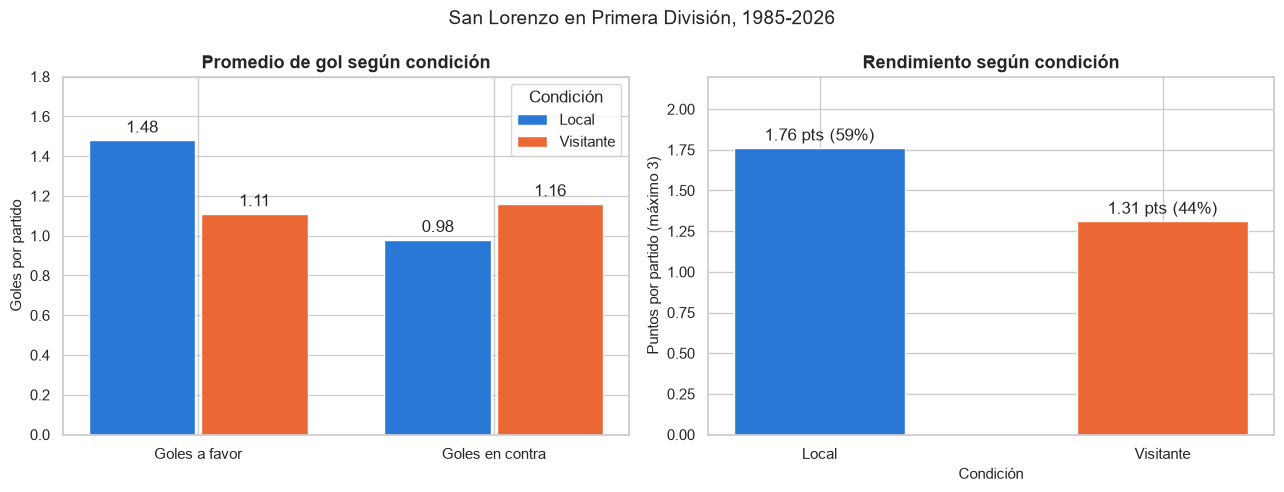

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: goles a favor y en contra por partido
metricas = ["goles_favor_prom", "goles_contra_prom"]
etiquetas = ["Goles a favor", "Goles en contra"]
x = np.arange(len(metricas))
ancho = 0.38
for i, condicion in enumerate(["Local", "Visitante"]):
    valores = resumen_condicion.loc[condicion, metricas].values
    barras = ax1.bar(x + (i - 0.5) * ancho, valores, width=ancho - 0.02,
                     color=COLORES_CONDICION[condicion], label=condicion)
    ax1.bar_label(barras, fmt="%.2f", padding=3)
ax1.set_xticks(x, etiquetas)
ax1.set_ylabel("Goles por partido")
ax1.set_title("Promedio de gol según condición")
ax1.set_ylim(0, 1.8)
ax1.legend(title="Condición")

# Panel derecho: puntos por partido
puntos = resumen_condicion["puntos_por_partido"]
barras = ax2.bar(puntos.index, puntos.values, width=0.5,
                 color=[COLORES_CONDICION[c] for c in puntos.index])
ax2.bar_label(barras, labels=[f"{p:.2f} pts ({e:.0f}%)" for p, e in
                               zip(puntos, resumen_condicion["efectividad_pct"])], padding=3)
ax2.set_ylabel("Puntos por partido (máximo 3)")
ax2.set_xlabel("Condición")
ax2.set_title("Rendimiento según condición")
ax2.set_ylim(0, 2.2)

fig.suptitle("San Lorenzo en Primera División, 1985-2026", fontsize=14)
plt.tight_layout()
plt.show()

**Lectura:** de local San Lorenzo convierte **un tercio más de goles** que de visitante (1,48 contra 1,11 por partido) y recibe menos (0,98 contra 1,16). Eso se traduce en una efectividad de **59% de local contra 44% de visitante**.

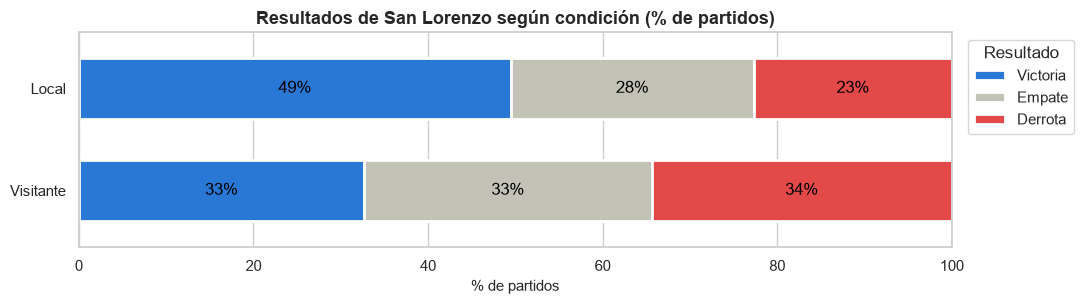

In [15]:
# Distribución de resultados (% de partidos) según condición
distribucion = pd.crosstab(df_lv["condicion"], df_lv["resultado"], normalize="index") * 100
distribucion = distribucion[["Victoria", "Empate", "Derrota"]]

ax = distribucion.plot(kind="barh", stacked=True, figsize=(11, 3.2), width=0.6,
                       color=[COLORES_RESULTADO[r] for r in distribucion.columns],
                       edgecolor="white", linewidth=2)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.0f%%", label_type="center", color="black")
ax.set_title("Resultados de San Lorenzo según condición (% de partidos)")
ax.set_xlabel("% de partidos")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(title="Resultado", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Lectura:** San Lorenzo gana **la mitad de sus partidos de local** y solo **un tercio de visitante**. La diferencia en derrotas también es grande.

### 5.2 Evolución año a año: local vs. visitante
Los valores anuales oscilan mucho, por eso agregamos el **promedio móvil de 3 años** (línea gruesa) para ver la tendencia. *2026 está incompleto (datos hasta octubre).*

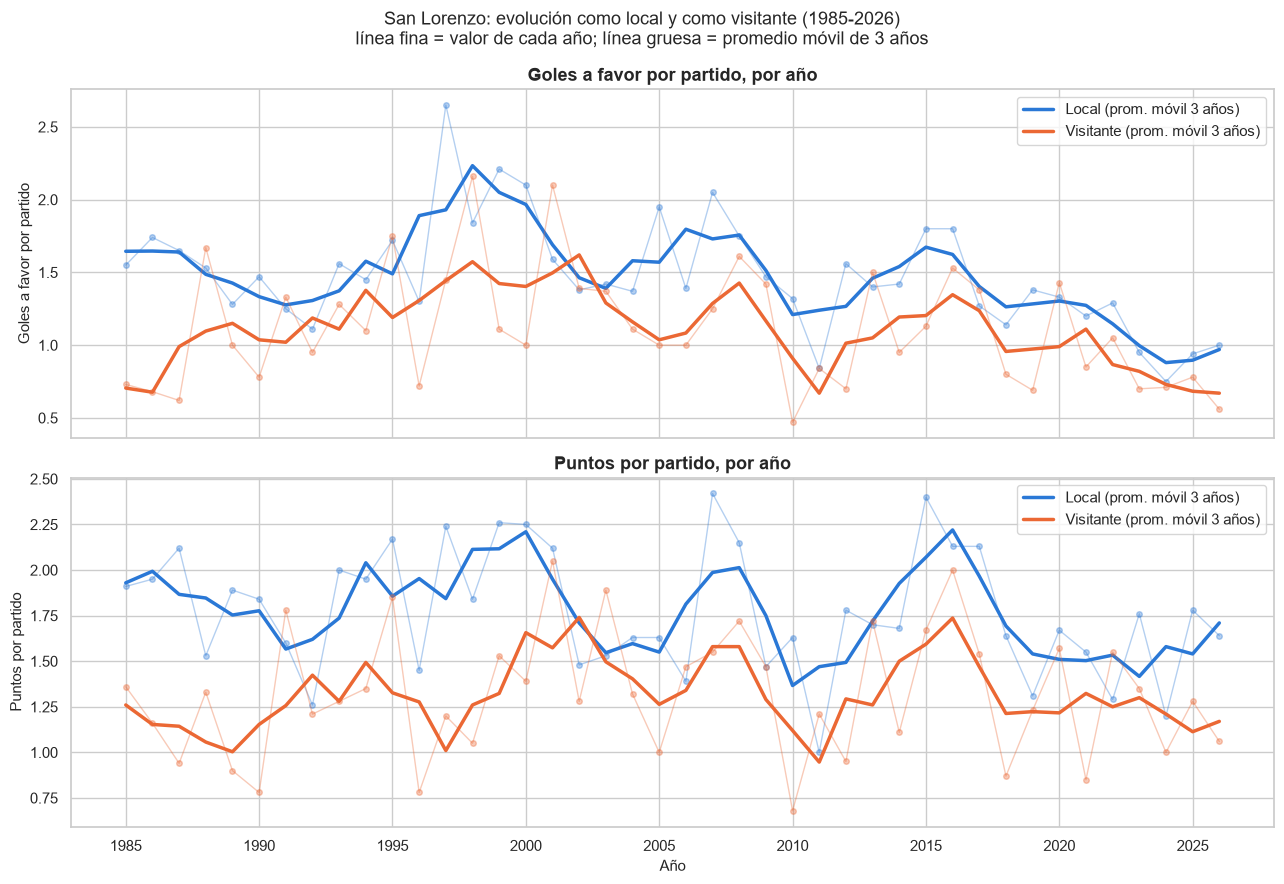

Ventaja de local en goles a favor por partido, por década:
condicion  Local  Visitante  diferencia
decada                                 
1980s       1.55       0.96        0.59
1990s       1.64       1.27        0.37
2000s       1.65       1.33        0.32
2010s       1.38       0.98        0.40
2020s       1.05       0.82        0.23


In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for condicion, color in COLORES_CONDICION.items():
    # Goles a favor por partido
    serie_goles = goles_anio_condicion[condicion]
    ax1.plot(serie_goles.index, serie_goles.values, color=color, alpha=0.35, linewidth=1,
             marker="o", markersize=4)
    ax1.plot(serie_goles.index, serie_goles.rolling(3, center=True, min_periods=2).mean(),
             color=color, linewidth=2.5, label=f"{condicion} (prom. móvil 3 años)")
    # Puntos por partido
    serie_puntos = puntos_anio_condicion[condicion]
    ax2.plot(serie_puntos.index, serie_puntos.values, color=color, alpha=0.35, linewidth=1,
             marker="o", markersize=4)
    ax2.plot(serie_puntos.index, serie_puntos.rolling(3, center=True, min_periods=2).mean(),
             color=color, linewidth=2.5, label=f"{condicion} (prom. móvil 3 años)")

ax1.set_title("Goles a favor por partido, por año")
ax1.set_ylabel("Goles a favor por partido")
ax1.legend(loc="upper right")
ax2.set_title("Puntos por partido, por año")
ax2.set_ylabel("Puntos por partido")
ax2.set_xlabel("Año")
ax2.legend(loc="upper right")
ax2.set_xticks(range(1985, 2027, 5))

fig.suptitle("San Lorenzo: evolución como local y como visitante (1985-2026)\n"
             "línea fina = valor de cada año; línea gruesa = promedio móvil de 3 años", fontsize=13)
plt.tight_layout()
plt.show()

# Brecha local - visitante por década
brecha = resumen_decada["goles_favor_prom"].unstack("condicion")
brecha["diferencia"] = brecha["Local"] - brecha["Visitante"]
print("Ventaja de local en goles a favor por partido, por década:")
print(brecha.round(2))

**Lectura:** la línea azul (local) queda casi siempre por encima de la naranja (visitante), tanto en goles como en puntos. La ventaja de local **existe en las cinco décadas**: es máxima en los 80 (+0,59 goles por partido) y mínima en los 2020 (+0,23). En los 2020 se achica porque **cae sobre todo el gol de local**, no porque mejore el de visitante. Desde 2010, y con más fuerza desde 2018, **ambas líneas bajan**: el equipo convierte cada vez menos en las dos condiciones.

### 5.3 Etapas históricas: promedio de gol por década

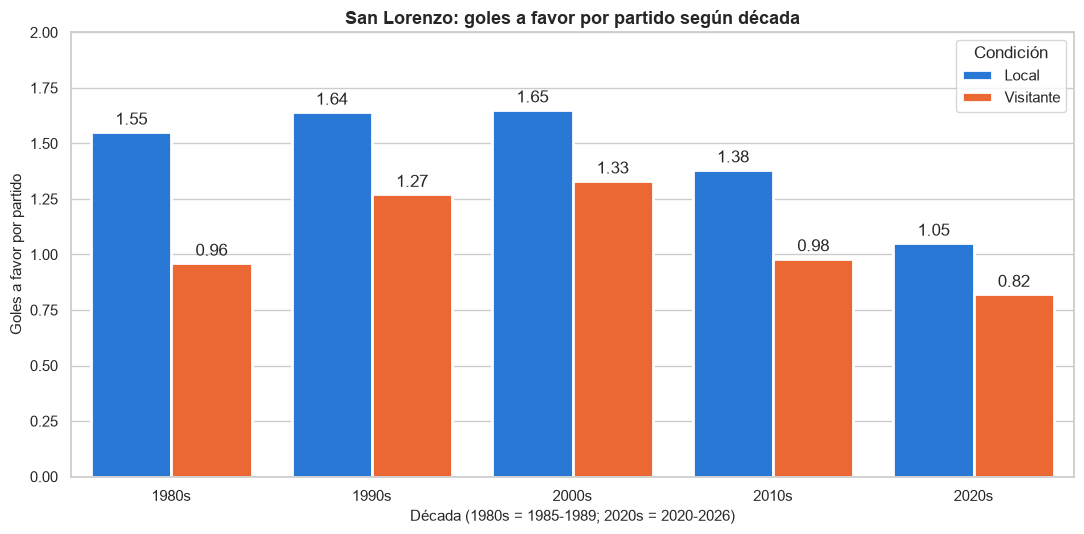

In [17]:
goles_decada = resumen_decada.reset_index()

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=goles_decada, x="decada", y="goles_favor_prom", hue="condicion",
                 palette=COLORES_CONDICION, saturation=1, edgecolor="white", linewidth=2)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", padding=3)
ax.set_title("San Lorenzo: goles a favor por partido según década")
ax.set_xlabel("Década (1980s = 1985-1989; 2020s = 2020-2026)")
ax.set_ylabel("Goles a favor por partido")
ax.set_ylim(0, 2)
ax.legend(title="Condición")
plt.tight_layout()
plt.show()

**Lectura:** las décadas de **1990 y 2000** son la etapa más goleadora del club (más de 1,6 goles por partido de local y alrededor de 1,3 de visitante). En los **2020** se registra el promedio más bajo de toda la serie, tanto de local como de visitante.

### 5.4 Promedio de gol y campañas exitosas
Comparamos la evolución anual del gol con el rendimiento en puntos y marcamos en amarillo los años en que San Lorenzo salió campeón de liga. Son dos gráficos separados con el mismo eje de años, porque se trata de dos medidas distintas.

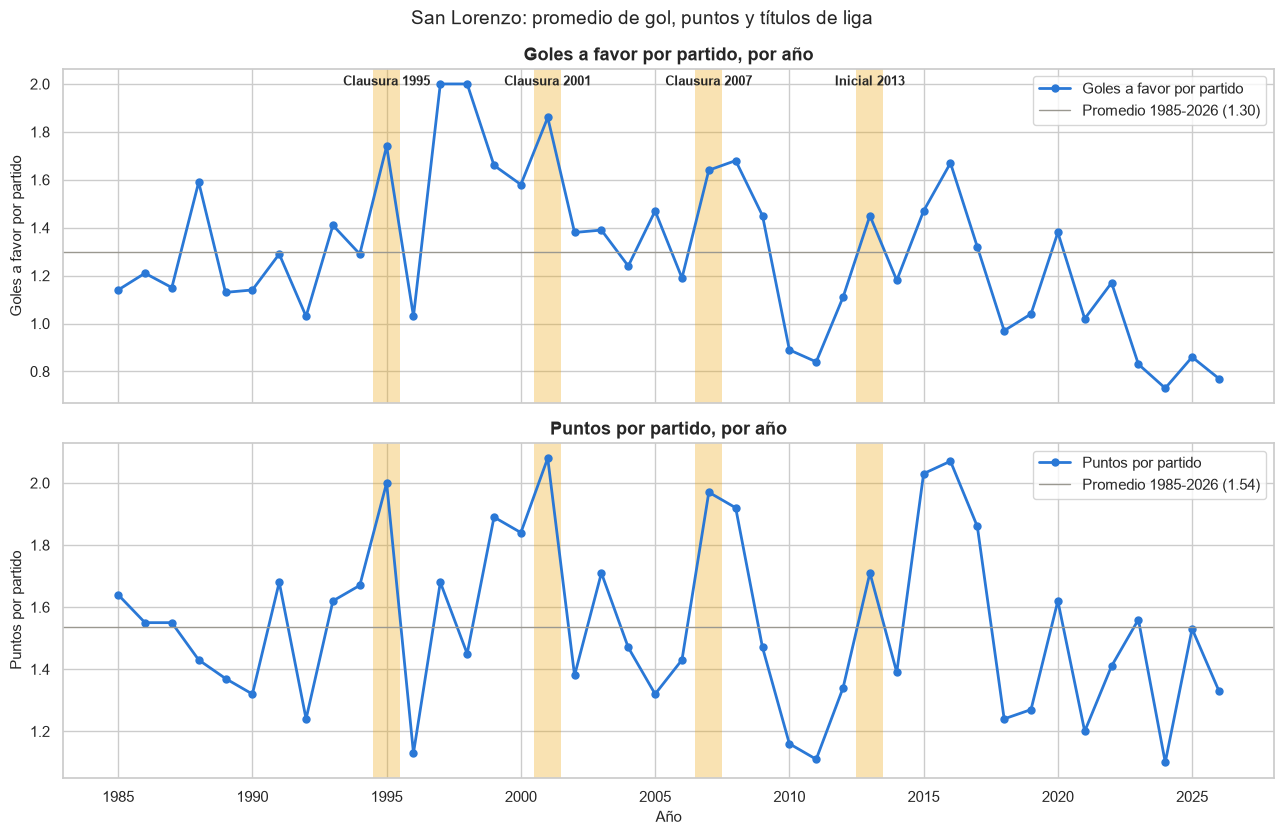

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)

ax1.plot(resumen_anual.index, resumen_anual["goles_favor_prom"], color=COLOR_LOCAL,
         linewidth=2, marker="o", markersize=5, label="Goles a favor por partido")
ax1.axhline(df_sl["goles_favor"].mean(), color=COLOR_NEUTRO, linewidth=1,
            label=f"Promedio 1985-2026 ({df_sl['goles_favor'].mean():.2f})")
ax1.set_title("Goles a favor por partido, por año")
ax1.set_ylabel("Goles a favor por partido")
ax1.legend(loc="upper right")

ax2.plot(resumen_anual.index, resumen_anual["puntos_por_partido"], color=COLOR_LOCAL,
         linewidth=2, marker="o", markersize=5, label="Puntos por partido")
ax2.axhline(df_sl["puntos"].mean(), color=COLOR_NEUTRO, linewidth=1,
            label=f"Promedio 1985-2026 ({df_sl['puntos'].mean():.2f})")
ax2.set_title("Puntos por partido, por año")
ax2.set_ylabel("Puntos por partido")
ax2.set_xlabel("Año")
ax2.legend(loc="upper right")
ax2.set_xticks(range(1985, 2027, 5))

# Franjas amarillas en los años con título de liga
nombre_por_anio = {temporada: nombre for (_, temporada), nombre in titulos.items()}
for anio in anios_titulo:
    for ax in (ax1, ax2):
        ax.axvspan(anio - 0.5, anio + 0.5, color=COLOR_TITULO, alpha=0.3, linewidth=0)
    ax1.annotate(nombre_por_anio[anio], xy=(anio, ax1.get_ylim()[1]), xytext=(0, -12),
                 textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

fig.suptitle("San Lorenzo: promedio de gol, puntos y títulos de liga", fontsize=14)
plt.tight_layout()
plt.show()

**Lectura:** los cuatro años con título están **por encima del promedio histórico en goles y en puntos**, y 1995, 2001 y 2007 son picos claros de puntos por partido. Sin embargo, **los años más goleadores (1997 y 1998, con 2 goles por partido) no terminaron en título**: el equipo convertía mucho pero también recibía mucho (más de 1,4 goles en contra por partido). También hay años de gran rendimiento sin título, como 2015 y 2016 (más de 2 puntos por partido).

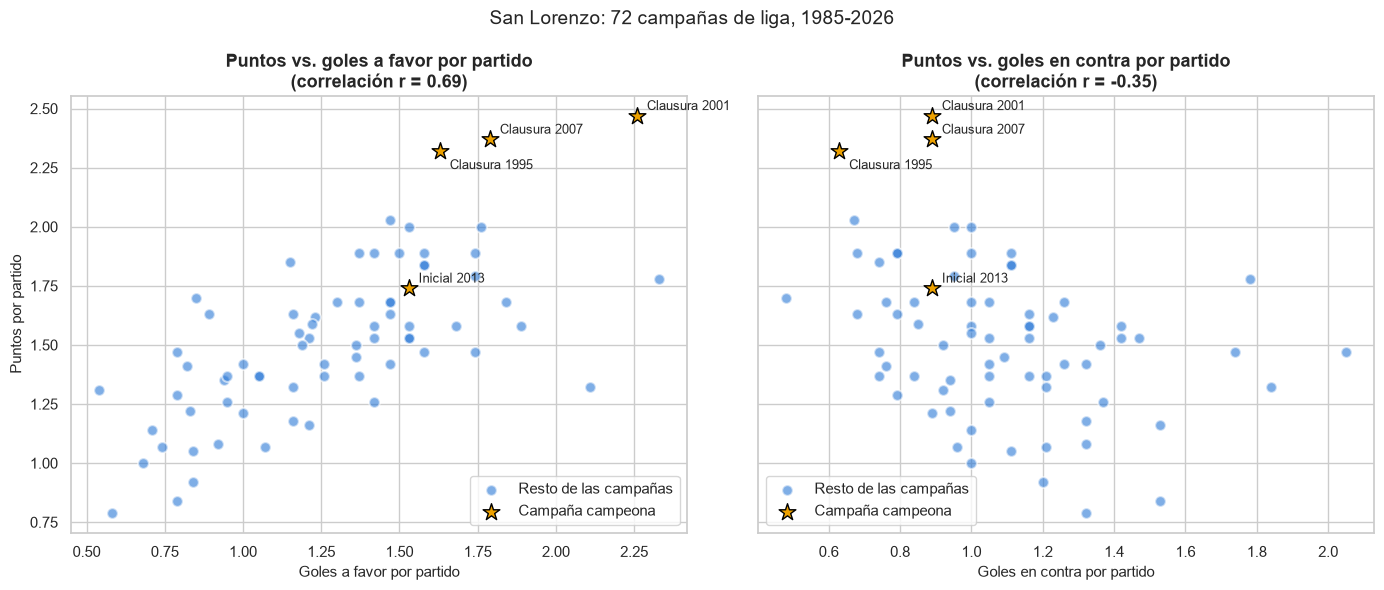

In [19]:
# Cada punto es una campaña (torneo) con al menos 10 partidos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
campeonas = campanias_completas[campanias_completas["titulo"]]
resto = campanias_completas[~campanias_completas["titulo"]]

for ax, columna, titulo_eje in [(ax1, "goles_favor_prom", "Goles a favor por partido"),
                                (ax2, "goles_contra_prom", "Goles en contra por partido")]:
    ax.scatter(resto[columna], resto["puntos_por_partido"], s=60, color=COLOR_LOCAL,
               alpha=0.6, edgecolor="white", linewidth=1.5, label="Resto de las campañas")
    ax.scatter(campeonas[columna], campeonas["puntos_por_partido"], s=160, color=COLOR_TITULO,
               edgecolor="black", linewidth=1, marker="*", label="Campaña campeona", zorder=3)
    for nombre, fila in campeonas.iterrows():
        # La etiqueta de 1995 va debajo para no tapar la estrella de 2007
        desplazamiento = (7, -13) if nombre == "Clausura 1995" else (7, 4)
        ax.annotate(nombre, (fila[columna], fila["puntos_por_partido"]), xytext=desplazamiento,
                    textcoords="offset points", fontsize=9)
    r = campanias_completas[columna].corr(campanias_completas["puntos_por_partido"])
    ax.set_title(f"Puntos vs. {titulo_eje.lower()}\n(correlación r = {r:.2f})")
    ax.set_xlabel(titulo_eje)
    ax.legend(loc="lower right" if columna == "goles_favor_prom" else "lower left")

ax1.set_ylabel("Puntos por partido")
fig.suptitle(f"San Lorenzo: {len(campanias_completas)} campañas de liga, 1985-2026", fontsize=14)
plt.tight_layout()
plt.show()

**Lectura:** hay una **relación positiva fuerte** entre convertir más y sumar más puntos (r = 0,69): el promedio de gol explica buena parte del rendimiento. La relación con los goles en contra es **negativa y más débil** (r = -0,35). Lo que distingue a las campañas campeonas es la **combinación** de ambas cosas: las cuatro recibieron **menos de 0,9 goles por partido**, y las tres de los Clausura además están entre las más goleadoras. En cambio, campañas muy goleadoras como el Apertura 1997 (2,33 goles por partido) no ganaron porque recibieron casi 1,8 goles por partido.

## 6. Conclusiones

Antes de responder las preguntas guía, reunimos en una tabla los indicadores clave calculados en el notebook.

In [20]:
# Indicadores clave para responder las preguntas guía
mejor_decada = resumen_decada["goles_favor_prom"].unstack("condicion").mean(axis=1).idxmax()
peor_decada = resumen_decada["goles_favor_prom"].unstack("condicion").mean(axis=1).idxmin()
campania_mas_goleadora = campanias_completas["goles_favor_prom"].idxmax()

indicadores = pd.Series({
    "Partidos analizados": len(df_sl),
    "Goles a favor por partido - Local": resumen_condicion.loc["Local", "goles_favor_prom"],
    "Goles a favor por partido - Visitante": resumen_condicion.loc["Visitante", "goles_favor_prom"],
    "Efectividad % - Local": resumen_condicion.loc["Local", "efectividad_pct"],
    "Efectividad % - Visitante": resumen_condicion.loc["Visitante", "efectividad_pct"],
    "Década más goleadora": mejor_decada,
    "Década menos goleadora": peor_decada,
    "Campaña más goleadora": campania_mas_goleadora,
    "Correlación goles a favor - puntos (campañas)":
        round(campanias_completas["goles_favor_prom"].corr(campanias_completas["puntos_por_partido"]), 2),
    "Correlación goles en contra - puntos (campañas)":
        round(campanias_completas["goles_contra_prom"].corr(campanias_completas["puntos_por_partido"]), 2),
})
display(indicadores.to_frame(name="valor"))

,valor
Partidos analizados,1506
Goles a favor por partido - Local,1.48
Goles a favor por partido - Visitante,1.11
Efectividad % - Local,58.75
Efectividad % - Visitante,43.64
Década más goleadora,2000s
Década menos goleadora,2020s
Campaña más goleadora,Apertura 1997
Correlación goles a favor - puntos (campañas),0.69
Correlación goles en contra - puntos (campañas),-0.35


### Pregunta 1: ¿Cómo varió el rendimiento y el promedio de gol de San Lorenzo como local y como visitante a lo largo de los años?

* **La localía pesa, y mucho.** En 1.504 partidos de Primera División (1985-2026), San Lorenzo convierte **1,48 goles por partido de local y 1,11 de visitante** (un 33% más en casa). También recibe menos: 0,98 contra 1,16.
* Esa diferencia se traslada al resultado: de local gana el **49%** de los partidos y obtiene el **59% de los puntos** en juego; de visitante gana el **33%** y obtiene el **44%**.
* **La ventaja de local es constante en el tiempo:** aparece en las cinco décadas. Fue máxima en los 80 (+0,59 goles por partido) y mínima en los 2020 (+0,23).
* **Tendencia:** el promedio de gol creció desde fines de los 80 hasta su punto más alto entre **1997 y 2001** y desde ahí bajó. Desde 2018 cae en las dos condiciones y los 2020 son la década menos goleadora (1,05 de local y 0,82 de visitante). La brecha de los 2020 es más chica porque **cayó el gol de local**, no porque haya mejorado el de visitante.

### Pregunta 2: ¿En qué etapas históricas San Lorenzo registró su mayor promedio de gol y cómo impactó en sus campañas más exitosas?

* La etapa más goleadora es la de **los 90 y los 2000** (alrededor de 1,65 goles por partido de local), con el pico en **1997-1998** (2 goles por partido en el año). Tres de los cuatro títulos de liga del período (**Clausura 1995, 2001 y 2007**) se ganaron dentro de esa etapa.
* **Hacer goles ayuda a ganar:** entre las 72 campañas, el promedio de gol y los puntos por partido tienen una correlación positiva fuerte (**r = 0,69**). El **Clausura 2001** es el mejor ejemplo: 2ª campaña más goleadora (2,26 goles por partido) y la de más puntos de toda la serie (2,47 por partido).
* **Pero el gol solo no alcanza.** La campaña más goleadora, el **Apertura 1997** (2,33 goles por partido), no terminó en título porque el equipo recibió casi 1,8 goles por partido. Las cuatro campañas campeonas comparten algo: recibieron **0,9 goles por partido o menos**. Por eso el Clausura 1995 (12º en promedio de gol) y el Inicial 2013 (17º) también fueron campeones.
* **En síntesis:** los títulos llegaron en las etapas de mayor promedio de gol, pero lo que los explica es la **combinación de gol y solidez defensiva**. Las etapas de menor gol, desde 2018, coinciden con un rendimiento más bajo y sin títulos de liga.

### Reflexión final y limitaciones del dataset

* **Fuente secundaria:** los datos vienen de Wikipedia y RSSSF, recopilados por un proyecto abierto. Pueden tener errores puntuales de carga.
* **Cobertura incompleta:** entre 1985 y 1992 la Primera División incluye solo la liga y faltan el Nacional 1985, las liguillas y las finales. **2026 está incompleto** (hasta octubre).
* **Formatos de torneo distintos** (temporadas largas, Apertura/Clausura, Inicial/Final, Copa de la Liga): por eso trabajamos con **promedios por partido** y no con totales.
* **Puntaje normalizado:** usamos 3 puntos por victoria en todas las épocas, aunque hasta 1995 se daban 2. Los puntos son comparables entre sí, pero no son los de la tabla oficial de cada torneo.
* **Los títulos se cargaron a mano**, porque el dataset no informa campeones. Tampoco incluye copas internacionales (por ejemplo, la Copa Libertadores 2014).
* **Lo que el dataset no permite medir:** no hay datos de jugadores, entrenadores, presupuesto ni contexto institucional, que probablemente explican buena parte de los cambios de rendimiento observados.